# DSA211: Diagnosing and Remedying Nonlinearity in Bike-Sharing Demand Models
## Notebook 06: Model Selection and Scoring

**Group 2**: Kok Wai Ying, Lee Sin Yang, Lim Wei Lun Marcus, Samuel Teo Yuzhen, Tee Jing Yuan

> **AI Coding Assistant Declaration**:
> In accordance with course guidelines, an AI coding assistant was used strictly for code scaffolding and plotting functions. All modeling decisions, interpretations, and written commentaries are independently authored by group members in the designated sections below (see [`agents.md`](../agents.md)).


### Planned Steps & Workflow (Referencing `docs/project_cv_workflow.html`)
- **1. Comprehensive CV Comparison (Workflow Step 5 & 6)**:
  - Assemble the CV results table comparing all candidate models from Notebooks 03, 04, and 05 (the full model ladder) on the shared expanding-window CV splits.
  - Display CV mean error and SE ($\text{SD}/\sqrt{8}$) for each model.
- **2. Winning Model Selection (Workflow Step 6)**:
  - Apply selection criteria: lowest mean CV error or the **One-SE Rule** ($\text{threshold} = \text{min}(\text{CV error}) + \text{SE}$).
  - Select the winner using training-data CV only and fix its specification for evaluation.
- **3. Refit Winner on All Training Data (Workflow Step 6)**:
  - Refit the winning model specification on the entire training set (all folds combined).
  - Freeze the model parameters, preprocessing, and hyperparameters.
- **4. Establish Audit Pass Criteria (Workflow "Did the audit pass?")**:
  - Fix pass criteria before scoring:
    1. Test score agrees with CV: test error falls roughly within $\text{CV mean} \pm 2\,\text{SE}$.
    2. Model beats baseline: test error clearly lower than training mean predictor $\text{MSE}_{\text{baseline}} = \frac{1}{n_{\text{test}}} \sum_{i \in \text{test}} (y_i - \bar{y}_{\text{train}})^2$.
- **5. Test Set Evaluation (Workflow Step 7)**:
  - Apply Notebook 02 base processing with the same fixed dummy levels, exclude the holiday main effect as in Notebooks 03–05, and apply the selected model's transformations.
  - Report the saved October–December test evaluation for the fixed winner; reuse the completed cache on subsequent runs. See the interpretation below for the history of the revised split and specification.
  - Report final out-of-sample metrics (count-scale RMSE, MAE, $R^2$).
  - Evaluate whether the audit passed and analyze performance during external shocks (e.g. Hurricane Sandy on Oct 29–30, 2012).
- **6. Final Full Refit on All Data (Workflow Step 8)**:
  - Refit the winning model specification on train + test combined ($N = 17,379$).
  - For an OLS winner, use `statsmodels` for final coefficient tables and conditional standard errors/confidence intervals. For a penalised winner, retain its exact estimator and report coefficients without substituting invalid ordinary OLS inference.
  - Retain Step 5 test score as the final reported out-of-sample performance figure.


## 1. Setup, declared metric and selection configuration

*Code: Generated by AI Assistant*

Implementation: comparison uses count-scale mean fold MSE; CV RMSE is its square root, and SE(MSE) is sample SD of the eight fold MSEs divided by sqrt(8). The configured rule is lowest mean CV MSE (one of the planned alternatives). No test result is used for selection. The exported scores are tuning/selection scores, not a nested-CV estimate of generalisation. The planned ±2 SE audit band is a heuristic, not a calibrated prediction interval for a later time block.

In [1]:
from pathlib import Path
import os, sys, json, hashlib, warnings, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.exceptions import ConvergenceWarning
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/data_utils.py').exists())
sys.path.insert(0, str(ROOT))
from src.data_utils import load_train_base, load_train, load_test, SPLIT_DATE
from src.cv_utils import get_cv_splitter
OUT = Path(os.environ.get('DSA211_06_OUTPUT_DIR', str(ROOT/'data')))
OUT.mkdir(parents=True, exist_ok=True)
SELECTION_RULE = 'minimum_mean_mse'
assert SELECTION_RULE == 'minimum_mean_mse'
# Required by the supplied audit plan; also report the numerical baseline improvement.
MIN_BASELINE_GAIN = 0.0
base_df = load_train_base().reset_index(drop=True)
raw_train = load_train().reset_index(drop=True)
# holiday is an exact combination (weekday_1..5 - workingday): drop it so the design is full rank and workingday stays explicit for hr x workingday
FEATURE_COLS = [c for c in base_df if c not in ['dteday','cnt','holiday']]
HR_COLS = [c for c in FEATURE_COLS if c.startswith('hr_')]
y_train = base_df['cnt'].to_numpy(dtype=float)
assert base_df['dteday'].is_monotonic_increasing
assert (base_df['dteday'] < SPLIT_DATE).all() and (y_train > 0).all()
cv = get_cv_splitter(base_df['dteday'])
folds = list(cv.split(base_df))
months = [base_df['dteday'].iloc[va].min().strftime('%Y-%m') for tr, va in folds]
assert len(folds) == 8
assert 'holiday' not in FEATURE_COLS and 'workingday' in FEATURE_COLS
# Every training row participates in training or validation in the month-aligned CV.
used_rows = np.unique(np.concatenate([idx for pair in folds for idx in pair]))
np.testing.assert_array_equal(used_rows, np.arange(len(base_df)))
for tr, va in folds:
    assert base_df['dteday'].iloc[tr].max() < base_df['dteday'].iloc[va].min()
print('Rule:', SELECTION_RULE, '| metric: count-scale MSE | folds:', months)
print('Training rows:', len(base_df), '| test set not loaded')

Rule: minimum_mean_mse | metric: count-scale MSE | folds: ['2012-02', '2012-03', '2012-04', '2012-05', '2012-06', '2012-07', '2012-08', '2012-09']
Training rows: 15211 | test set not loaded


## 2. Reproduce preprocessing and candidate specifications from Notebooks 02–05

*Code: Generated by AI Assistant*

The fixed category levels and base-data column order match Notebook 02. Its exported data still contains `holiday`; it is excluded when constructing every model matrix, matching Notebooks 03–05. In this dataset, `holiday = weekday_1 + ... + weekday_5 - workingday`, so removing the separate holiday column resolves the exact redundancy while retaining `workingday` for the hour-by-working-day interactions. The base, M3 and M4 designs contain 48, 51 and 74 predictors, respectively.

Polynomial features are uncentred degree-2 terms, matching the fitted Notebook 04/05 specifications. Scaling is fitted inside each training fold. The checks below verify full rank on the full training set and in every CV training window, and confirm that dropping the redundant holiday column leaves M1's training fitted values unchanged. Ridge and LASSO scores must still be checked against the updated Notebook 05 export because a penalty can respond to the changed parameterisation.


In [2]:
LEVELS = {'hr': list(range(24)), 'mnth': list(range(1,13)),
          'weekday': list(range(7)), 'weathersit': [1,2,3,4]}
KEEP = ['yr','holiday','workingday','temp','hum','windspeed']
def base_process(raw):
    raw = raw.reset_index(drop=True)
    for c, levels in LEVELS.items():
        if not raw[c].isin(levels).all():
            raise ValueError(f'Unexpected/missing category in {c}')
    cats = pd.DataFrame({c: pd.Categorical(raw[c], categories=v) for c,v in LEVELS.items()})
    dummy = pd.get_dummies(cats, prefix=list(LEVELS), drop_first=True, dtype=int)
    result = pd.concat([raw[['dteday','cnt']], dummy, raw[KEEP]], axis=1)
    assert list(result.columns) == list(base_df.columns)
    assert not result.isna().any().any()
    return result
pd.testing.assert_frame_equal(base_process(raw_train), base_df, check_dtype=False)

def design(base, space):
    X = base[FEATURE_COLS].astype(float).copy()
    if space in ['m3','m4']:
        for c in ['temp','hum','windspeed']:
            X[f'{c}^2'] = X[c] ** 2
    if space == 'm4':
        inter = X[HR_COLS].mul(X['workingday'], axis=0)
        inter.columns = [f'{c}:workingday' for c in HR_COLS]
        X = pd.concat([X, inter], axis=1)
    return X

def make_estimator(spec):
    if spec['kind'] == 'ols':
        return Pipeline([('reg', LinearRegression())])
    reg = (Ridge(alpha=spec['alpha']) if spec['kind']=='ridge'
           else Lasso(alpha=spec['alpha'], max_iter=20000, precompute=True))
    return Pipeline([('scale', StandardScaler()), ('reg', reg)])

def fit_candidate(spec, base):
    X = design(base, spec['space'])
    y = base['cnt'].to_numpy(dtype=float)
    target = np.log(y) if spec['log_target'] else y
    with warnings.catch_warnings():
        warnings.simplefilter('error', ConvergenceWarning)
        estimator = make_estimator(spec).fit(X, target)
    sigma2 = None
    if spec['log_target']:
        resid = target - estimator.predict(X)
        if spec['kind']=='ols':
            p = np.linalg.matrix_rank(np.column_stack([np.ones(len(X)),X]))
        elif spec['kind']=='ridge':
            p = X.shape[1] + 1  # Notebook 05 convention, not effective Ridge df
        else:
            p = np.count_nonzero(estimator.named_steps['reg'].coef_) + 1
        assert len(X) > p
        sigma2 = float(resid @ resid / (len(X)-p))
    return estimator, sigma2

def predict_count(spec, estimator, sigma2, base):
    pred = estimator.predict(design(base, spec['space']))
    pred = np.exp(pred + sigma2/2) if spec['log_target'] else pred
    assert np.isfinite(pred).all()
    return pred

specs = {f'M{i} OLS': {'kind':'ols','space':space,'alpha':None,'log_target':i>1}
         for i,space in enumerate(['base','base','m3','m4'],1)}
# Exact grid entries identified by Notebook 05's saved tuning summary (not rounded printed values).
ridge_grid = np.logspace(-4,4,41)
lasso_grid = np.logspace(-5,-0.5,31)
choices = {('ridge','base'):(37,38), ('ridge','m4'):(0,39),
           ('lasso','base'):(24,26), ('lasso','m4'):(16,24)}
for (kind,space), indices in choices.items():
    grid = ridge_grid if kind=='ridge' else lasso_grid
    for rule,idx in zip(['min','1se'],indices):
        specs[f'{kind.capitalize()} {space} ({rule})'] = {
            'kind':kind,'space':space,'alpha':float(grid[idx]),'log_target':True}
display(pd.DataFrame(specs).T)
# Verify Notebook 03's cleaned M1 has the same fitted values as the exported M1 reference.
X = design(base_df,'base')
a = LinearRegression().fit(X,y_train).predict(X)
X_all = base_df.drop(columns=['dteday','cnt']).astype(float)  # includes holiday
b = LinearRegression().fit(X_all,y_train).predict(X_all)
np.testing.assert_allclose(a,b,atol=1e-6,rtol=1e-7)
# Verify the cleaned feature spaces before fitting or checking any candidate.
rank_checks = []
for space, expected_predictors in [('base', 48), ('m3', 51), ('m4', 74)]:
    X_check = design(base_df, space)
    assert 'holiday' not in X_check.columns and 'workingday' in X_check.columns
    assert X_check.shape[1] == expected_predictors
    full_rank = np.linalg.matrix_rank(np.column_stack([np.ones(len(X_check)), X_check]))
    assert full_rank == expected_predictors + 1, f'Rank deficiency in {space}'
    for tr, _ in folds:
        fold_X = X_check.iloc[tr]
        assert np.linalg.matrix_rank(np.column_stack([np.ones(len(fold_X)), fold_X])) == expected_predictors + 1
    rank_checks.append({'space': space, 'predictors': expected_predictors,
                        'rank_with_intercept': full_rank, 'all_cv_training_windows_full_rank': True})
display(pd.DataFrame(rank_checks).set_index('space'))


,kind,space,alpha,log_target
M1 OLS,ols,base,None,False
M2 OLS,ols,base,None,True
M3 OLS,ols,m3,None,True
M4 OLS,ols,m4,None,True
Ridge base (min),ridge,base,2511.886432,True
Ridge base (1se),ridge,base,3981.071706,True
Ridge m4 (min),ridge,m4,0.0001,True
Ridge m4 (1se),ridge,m4,6309.573445,True
Lasso base (min),lasso,base,0.039811,True
Lasso base (1se),lasso,base,0.079433,True


,predictors,rank_with_intercept,all_cv_training_windows_full_rank
space,,,
base,48,49,True
m3,51,52,True
m4,74,75,True


## 3. Comprehensive CV comparison and reproducibility checks

*Code: Generated by AI Assistant*

,cv_mse,sd_mse,folds,se_mse,cv_rmse,se_rmse_delta
model,,,,,,
Lasso m4 (min),12251.016,11206.365,8,3962.048,110.684,17.898
M4 OLS,13330.003,12377.965,8,4376.271,115.456,18.952
Ridge m4 (min),13330.005,12377.967,8,4376.272,115.456,18.952
Lasso m4 (1se),14891.461,5839.631,8,2064.621,122.031,8.459
Ridge m4 (1se),16111.803,5793.243,8,2048.221,126.932,8.068
M1 OLS,17125.202,5324.926,8,1882.646,130.863,7.193
Ridge base (min),18367.945,5285.123,8,1868.573,135.528,6.894
Ridge base (1se),18714.096,5190.602,8,1835.155,136.799,6.707
Lasso base (min),20160.761,7721.430,8,2729.938,141.989,9.613


,comparison,mean_MSE_improvement,paired_SE,gain_in_paired_SEs,folds_better,folds
0,LASSO M4 (min) vs OLS M4,1078.988,703.615,1.533,6,8


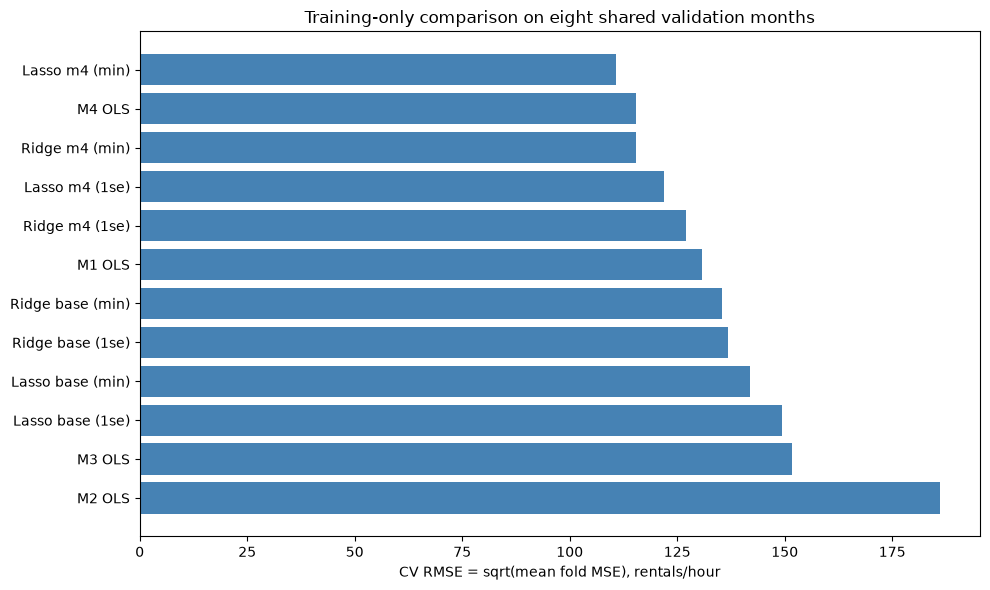

In [3]:
export_path = ROOT/'data/cv_results_05_regularization.csv'
export = pd.read_csv(export_path)
assert set(export['model']) == set(specs)
assert not export.duplicated(['model','fold']).any()
assert np.isfinite(export['mse']).all() and (export['mse'] >= 0).all()
for label,g in export.groupby('model'):
    g = g.sort_values('fold')
    assert g['fold'].tolist() == list(range(1,9))
    assert g['val_month'].tolist() == months
# Recompute only the fixed exported candidates; do not re-tune on these results.
checks = []
for label,spec in specs.items():
    expected = export[export['model']==label].sort_values('fold')['mse'].to_numpy()
    actual = []
    for tr,va in folds:
        est,s2 = fit_candidate(spec,base_df.iloc[tr])
        pred = predict_count(spec,est,s2,base_df.iloc[va])
        actual.append(mean_squared_error(y_train[va],pred))
    np.testing.assert_allclose(actual,expected,rtol=2e-4,atol=0.05,
                               err_msg=f'Export mismatch: {label}; stop before test access')
    checks.append({'model':label,'max_abs_MSE_difference':float(np.max(np.abs(np.array(actual)-expected)))})
summary = export.groupby('model')['mse'].agg(['mean','std','count'])
summary.columns = ['cv_mse','sd_mse','folds']
summary['se_mse'] = summary['sd_mse']/np.sqrt(summary['folds'])
summary['cv_rmse'] = np.sqrt(summary['cv_mse'])
summary['se_rmse_delta'] = summary['se_mse']/(2*summary['cv_rmse'])
summary = summary.sort_values('cv_mse')
display(summary.round(3))
# Paired differences use the same validation months; this SE is not the model's own SE.
paired_folds = export.pivot(index='fold', columns='model', values='mse').sort_index()
paired_gain = paired_folds['M4 OLS'] - paired_folds['Lasso m4 (min)']
paired_se = float(paired_gain.std(ddof=1) / np.sqrt(len(paired_gain)))
paired_comparison = pd.DataFrame([{
    'comparison': 'LASSO M4 (min) vs OLS M4',
    'mean_MSE_improvement': float(paired_gain.mean()),
    'paired_SE': paired_se,
    'gain_in_paired_SEs': float(paired_gain.mean() / paired_se),
    'folds_better': int((paired_gain > 0).sum()),
    'folds': len(paired_gain),
}])
display(paired_comparison.round(3))
summary.to_csv(OUT/'notebook06_cv_comparison.csv')
pd.DataFrame(checks).to_csv(OUT/'notebook06_cv_reproduction_checks.csv',index=False)
fig,ax = plt.subplots(figsize=(10,6))
ax.barh(summary.index[::-1],summary['cv_rmse'].iloc[::-1],color='steelblue')
ax.set_xlabel('CV RMSE = sqrt(mean fold MSE), rentals/hour')
ax.set_title('Training-only comparison on eight shared validation months')
fig.tight_layout()
plt.show()

### Interpretation & Modeling Decisions: CV comparison
Author: Samuel Teo Yuzhen

The comparison covers the 12 candidates exported by Notebook 05: the four OLS models (M1–M4) and the minimum-error and one-SE penalty choices for Ridge and LASSO in the base and M4 feature spaces. All candidates use the same eight expanding-window validation months, February to September 2012. Errors are evaluated on the rental-count scale, including back-transformed predictions from log-response models. Each month receives equal weight in mean fold MSE. CV RMSE is the square root of this mean, rather than the mean of the monthly RMSEs. The fixed candidates reproduce Notebook 05's exported fold scores within the numerical tolerance of the verification check. Notebook 03 now uses the same square-root-of-mean-MSE summary as Notebooks 04–06, so M1 is compared on the same metric definition.

The baseline M1 has CV RMSE 130.86 rentals/hour. The log-response model M2 increases this to 186.11, so the log transformation alone worsens count-scale predictive performance. Adding quadratic weather terms (M3) reduces RMSE to 151.75, but this remains worse than M1. Adding hour-by-working-day interactions (M4) then reduces RMSE to 115.46, approximately 15.41 rentals/hour below M1. Thus, in the evaluated sequence, the log model with quadratic terms does not recover baseline performance; the specification containing both quadratic terms and interactions does. An interaction-only log model was not included in this comparison, so its performance cannot be inferred.

The apparent size of the two improvements depends on the metric. On the primary selection metric, MSE, the quadratic step (M2→M3) reduces error by 11,606.84, compared with 9,698.70 for the interaction step (M3→M4). On RMSE, the corresponding reductions are 34.35 and 36.30. It would therefore be misleading to describe the interaction step as providing the largest improvement without specifying the metric. Both steps improve on their preceding specification, although their contributions need not be independent of the order in which they were introduced.

Using the base features, Ridge has CV RMSEs of 135.53 and 136.80 for its minimum-error and one-SE choices; the corresponding LASSO results are 141.99 and 149.35. These improve on log-response OLS M2 but not count-response M1. Using the M4 features, Ridge has CV RMSEs of 115.46 and 126.93, while LASSO has 110.68 and 122.03. The one-SE choices accept higher mean error in exchange for stronger regularisation within the CV tolerance for each model family and feature set. Minimum-error Ridge M4 performs almost identically to OLS M4.

Average performance also conceals substantial monthly variation. M4's fold-MSE SD is approximately 12,378, versus 5,325 for M1. These standard deviations describe variability in each model's monthly errors; they do not directly measure uncertainty in the difference between models. Comparisons should use paired monthly differences because the models share the same validation folds.

Among the 12 exported candidates, LASSO M4 at the minimum-error penalty has the lowest CV RMSE, 110.68, with mean MSE 12,251.02 and SE(MSE) 3,962.05. Its mean MSE is approximately 8.1% lower than OLS M4's. The paired monthly MSE improvement averages 1,078.99, with a descriptive paired SE of 703.62. The mean improvement is therefore approximately 1.53 paired SEs, and LASSO performs better in six of eight months. The paired comparison is displayed above; its SE is distinct from the SE of a single model's mean MSE. This supports selection under the minimum-error rule, rather than conclusive superiority. The fold SEs are descriptive because time-ordered validation periods can be dependent and training windows overlap. Settings were also tuned on these folds, so the reported errors are selection scores, not an unbiased nested-CV estimate.


## 4. Declare one winner, refit all training data and freeze audit criteria

*Code: Generated by AI Assistant*

In [4]:
winner = str(summary.index[0])
spec = specs[winner].copy()
winner_stats = summary.loc[winner]
# MSE units on both sides of the audit band.
audit_low = max(0.,float(winner_stats.cv_mse - 2*winner_stats.se_mse))
audit_high = float(winner_stats.cv_mse + 2*winner_stats.se_mse)
train_est, train_sigma2 = fit_candidate(spec,base_df)
contract = {
    'selection_rule':SELECTION_RULE,'winner':winner,
    'specification':spec,'metric':'count-scale mean fold MSE','fold_months':months,
    'cv_mse':float(winner_stats.cv_mse),'cv_rmse':float(winner_stats.cv_rmse),
    'se_mse':float(winner_stats.se_mse),'audit_mse_band':[audit_low,audit_high],
    'minimum_relative_baseline_gain':MIN_BASELINE_GAIN,
    'training_mean':float(y_train.mean()),'training_rows':len(base_df),
    'base_features':FEATURE_COLS,'design_features':list(design(base_df,spec['space']).columns),
    'sigma2_training':train_sigma2,
    'training_sha256':hashlib.sha256((ROOT/'data/train_base.csv').read_bytes()).hexdigest(),
    'cv_export_sha256':hashlib.sha256(export_path.read_bytes()).hexdigest(),
}
contract_json = json.dumps(contract,sort_keys=True,indent=2)
contract_hash = hashlib.sha256(contract_json.encode()).hexdigest()
contract_path = OUT/'notebook06_selection_frozen.json'
def verify_frozen_contract(frozen, current):
    assert frozen.keys() == current.keys(), 'Frozen specification fields changed.'
    data_paths = {'training_sha256': ROOT/'data/train_base.csv',
                  'cv_export_sha256': export_path}
    numeric_fields = {'cv_mse', 'cv_rmse', 'se_mse', 'audit_mse_band',
                      'training_mean', 'sigma2_training'}
    for key in current:
        if key in data_paths:
            # Git may normalise CRLF to LF. Accept only identical bytes modulo line endings.
            raw_bytes = data_paths[key].read_bytes()
            lf_bytes = raw_bytes.replace(b'\r\n', b'\n')
            variants = [raw_bytes, lf_bytes, lf_bytes.replace(b'\n', b'\r\n')]
            valid_hashes = {hashlib.sha256(b).hexdigest() for b in variants}
            assert current[key] == hashlib.sha256(raw_bytes).hexdigest()
            assert frozen[key] in valid_hashes, f'{key}: data changed; do not reuse the test set.'
        elif key in numeric_fields and current[key] is not None and frozen[key] is not None:
            # Allow round-off only, not a materially different fit or CV result.
            np.testing.assert_allclose(current[key], frozen[key], rtol=1e-12, atol=1e-14,
                                       err_msg=f'{key}: frozen calculation changed')
        else:
            assert frozen[key] == current[key], f'{key}: frozen specification changed'

if contract_path.exists():
    frozen_text = contract_path.read_text()
    frozen_contract = json.loads(frozen_text)
    verify_frozen_contract(frozen_contract, contract)
    # Keep the original contract and hash: never migrate or reset an existing audit.
    contract = frozen_contract
    contract_json = frozen_text
    contract_hash = hashlib.sha256(frozen_text.encode()).hexdigest()
else:
    contract_path.write_text(contract_json)
print('Selected model:', winner, '| settings:', spec)
print('CV RMSE:', contract['cv_rmse'], '| predeclared MSE band:', [audit_low, audit_high])
print('Selection and training fit verified against the frozen specification.')

Selected model: Lasso m4 (min) | settings: {'kind': 'lasso', 'space': 'm4', 'alpha': 0.0025118864315095794, 'log_target': True}
CV RMSE: 110.68430665173133 | predeclared MSE band: [4326.919239281901, 20175.11223866709]
Selection and training fit verified against the frozen specification.


### Interpretation & Modeling Decisions: Winning model and predeclared audit criteria
Author: Samuel Teo Yuzhen

The implemented selection rule is lowest mean count-scale CV MSE, one of the alternatives in the planned workflow. It selects LASSO M4 with alpha = 0.0025118864. Selection follows this numerical rule despite the modest and variable advantage over OLS M4; it does not establish that LASSO is uniformly better across time periods. The one-SE penalty candidates are included in the comparison, but a cross-model one-SE rule is not used to choose the winner.

The selected specification uses log(cnt), the 48 base predictors after excluding the holiday main effect, uncentred quadratic terms for temperature, humidity and wind speed, and hour-by-working-day interactions. Predictors are standardised inside the estimator. Predictions are returned to the rental-count scale using the same training-residual variance correction as Notebook 05. The choice of uncentred features and the variance-correction convention are retained so that the audited model matches the candidate evaluated during selection.

The selected model was fitted on all 15,211 training observations dated before 1 October 2012. Its specification and penalty were fixed following cross-validation, and its training-estimated preprocessing and retransformation correction were applied unchanged to the October–December test set. The training-fitted correction multiplier, exp(sigma²/2), is approximately 1.0802. The final candidate selection uses training-data CV, and the subsequent full-data refit retains the selected specification and penalty.

The frozen specification records two audit checks. First, test MSE should fall within the approximate CV mean MSE ± 2 SE band: 4,326.92 to 20,175.11, on the squared rentals-per-hour scale. This is a course-workflow heuristic, not a calibrated confidence or prediction interval for a later time block. Second, test MSE should be lower than that of a constant prediction equal to the training mean, 185.23 rentals/hour. The programmed threshold is any positive improvement over that benchmark; the actual percentage improvement is reported separately to distinguish a numerical pass from a practically substantial gain.


## 5. Test evaluation and exact-specification full-data refit

*Code: Generated by AI Assistant*

For the current specification, this cell loads the saved evaluation when a completed cache is present. Only an initial run without a cache or guard reads the locked test data and computes predictions for the fixed winner and required training-mean benchmark. It reuses those predictions for all audit summaries. An on-disk guard prevents accidental repeated test evaluation. Completed runs reload saved results without reading the test set. A failed or interrupted audit must not be silently reset. Final refit uses the unchanged specification; if the audit fails, it is saved for the course deliverable but marked not validated for deployment. Passing these two checks is a limited project audit, not comprehensive deployment validation. Final-fit training scores are not reported as held-out performance. The guard controls reruns of the current specification; it does not erase earlier evaluations under previous splits or predictor sets.

In [5]:
CACHE = OUT/'notebook06_completed_run.pkl'
GUARD = OUT/'notebook06_test_access_started.json'
if CACHE.exists():
    with CACHE.open('rb') as f:
        results = pickle.load(f)  # Trusted local artifact created by this notebook only.
    assert results['contract_hash']==contract_hash
    assert results['specification'] == spec
    assert list(results['training_model'].feature_names_in_) == contract['design_features']
    assert list(results['full_model'].feature_names_in_) == contract['design_features']
    assert 'holiday' not in results['coefficients'].index
    assert results['full_rows'] == len(base_df) + results['audit']['n_test']
    # Confirm the reproduced training fit agrees with the cached model, without test access.
    X_train_check = design(base_df, spec['space'])
    np.testing.assert_allclose(train_est.predict(X_train_check),
                               results['training_model'].predict(X_train_check),
                               rtol=1e-10, atol=1e-10)
    print('Loaded the completed audit and full refit; test set NOT reopened.')
else:
    if GUARD.exists():
        raise RuntimeError('A previous audit started without a completed cache. Preserve the guard and investigate; do not rescore.')
    # Exclusive creation: a second execution cannot open the holdout concurrently.
    with GUARD.open('x') as f:
        json.dump({'contract_hash':contract_hash,'winner':winner},f)
    test_raw = load_test()  # The only call that reads the locked test set.
    assert (test_raw['dteday'] >= SPLIT_DATE).all()
    test_base = base_process(test_raw)
    y_test = test_base['cnt'].to_numpy(dtype=float)
    test_pred = predict_count(spec,train_est,train_sigma2,test_base)
    mse = float(mean_squared_error(y_test,test_pred))
    baseline_mse = float(np.mean((y_test-y_train.mean())**2))
    gain = float(1-mse/baseline_mse)
    audit = {'model':winner,'n_test':len(y_test),'test_mse':mse,'test_rmse':float(np.sqrt(mse)),
             'test_mae':float(mean_absolute_error(y_test,test_pred)),
             'test_r2':float(r2_score(y_test,test_pred)),
             'baseline_mse':baseline_mse,'relative_baseline_gain':gain,
             'within_cv_band':bool(audit_low<=mse<=audit_high),
             'beats_baseline':bool(gain>MIN_BASELINE_GAIN)}
    audit['audit_passed'] = audit['within_cv_band'] and audit['beats_baseline']
    predictions = test_raw[['dteday','hr']].copy()
    predictions['actual'] = y_test; predictions['predicted'] = test_pred
    predictions['residual'] = y_test-test_pred
    # Descriptive subsets of the same predictions, never selection criteria.
    sandy = test_raw['dteday'].between('2012-10-29','2012-10-30').to_numpy()
    event_rows = []
    for label,mask in [('Oct 29–30 (Sandy dates)',sandy),('Other test dates',~sandy)]:
        if mask.any():
            event_rows.append({'period':label,'n':int(mask.sum()),
                              'rmse':float(np.sqrt(np.mean((y_test[mask]-test_pred[mask])**2))),
                              'mae':float(np.mean(np.abs(y_test[mask]-test_pred[mask]))),
                              'mean_actual':float(y_test[mask].mean()),
                              'mean_predicted':float(test_pred[mask].mean())})
    full_base = pd.concat([base_df,test_base],ignore_index=True)
    full_est,full_sigma2 = fit_candidate(spec,full_base)
    X_full = design(full_base,spec['space'])
    reg = full_est.named_steps['reg']
    if spec['kind']=='ols':
        sm_fit = sm.OLS(full_base['cnt'] if not spec['log_target'] else np.log(full_base['cnt']),
                        sm.add_constant(X_full,has_constant='add')).fit()
        np.testing.assert_allclose(sm_fit.predict(),full_est.predict(X_full),atol=1e-5,rtol=1e-6)
        coefficients = pd.DataFrame({'coefficient':sm_fit.params,'std_error':sm_fit.bse,
                                    'ci_lower':sm_fit.conf_int()[0],'ci_upper':sm_fit.conf_int()[1]})
        coefficient_note = 'Conventional OLS inference; conditional on the selected specification and OLS error assumptions. Rank-deficient designs do not have unique coefficients.'
    else:
        scaler = full_est.named_steps['scale']
        coef = reg.coef_/scaler.scale_
        intercept = float(reg.intercept_ - np.dot(coef,scaler.mean_))
        coefficients = pd.DataFrame({'coefficient':np.r_[intercept,coef]},index=['const',*X_full.columns])
        np.testing.assert_allclose(intercept + X_full.to_numpy()@coef,full_est.predict(X_full),atol=1e-8)
        coefficient_note = 'Penalised coefficients on the original feature scales (log-response scale). Ordinary OLS standard errors/CIs are not valid for the selected penalised estimator; they are deliberately not substituted.'
    results = {'contract_hash':contract_hash,'audit':audit,'predictions':predictions,
               'events':pd.DataFrame(event_rows),'coefficients':coefficients,
               'coefficient_note':coefficient_note,'full_rows':len(full_base),
               'training_model':train_est,'full_model':full_est,'full_sigma2':full_sigma2,
               'specification':spec,'deployment_validated':audit['audit_passed']}
    # Persist the completed result before display/export so reruns do not rescore.
    with (OUT/'notebook06_completed_run.tmp').open('wb') as f:
        pickle.dump(results,f)
    (OUT/'notebook06_completed_run.tmp').replace(CACHE)
    print('Single audit and unchanged full-data refit completed.')

display(pd.DataFrame([results['audit']]))
display(results['events'])
print('Recorded dates only; missing hours are not imputed as zero demand.')
if not results['audit']['audit_passed']:
    print('AUDIT FAILED: retain the original score; do not tune against or rescore this holdout.')

Loaded the completed audit and full refit; test set NOT reopened.
Recorded dates only; missing hours are not imputed as zero demand.


,model,n_test,test_mse,test_rmse,test_mae,test_r2,baseline_mse,relative_baseline_gain,within_cv_band,beats_baseline,audit_passed
0,Lasso m4 (min),2168,6064.994636,77.878075,47.864632,0.850752,41790.948118,0.854873,True,True,True


,period,n,rmse,mae,mean_actual,mean_predicted
0,Oct 29–30 (Sandy dates),12,139.227368,98.149596,93.166667,177.927412
1,Other test dates,2156,77.400655,47.584753,219.897959,230.813432


### Interpretation & Modeling Decisions: Test audit and external-shock period
Author: Samuel Teo Yuzhen

The saved evaluation of the training-fitted model covers the 2,168 test observations from 1 October to 31 December 2012, using the same category levels, feature order and transformations as the training pipeline. Test RMSE is 77.88 rentals/hour, MAE is 47.86 rentals/hour, and R² is 0.851. The mean absolute prediction error is therefore about 48 rentals per recorded hour. The higher RMSE gives greater weight to the larger errors. R² compares squared error with variation around the test-set mean; it does not measure a causal explanation of demand.

Test MSE is 6,064.99, inside the frozen audit band. The training-mean benchmark has test MSE 41,790.95, so the winner reduces squared error by approximately 85.49% relative to this benchmark. This benchmark uses the training-set mean, whereas R² uses the test-set mean, so the two percentage improvements have different reference predictions. Both programmed checks pass; this does not by itself establish suitability for deployment. The lower test RMSE than CV RMSE does not establish consistently better performance in future periods, because the periods differ in demand and conditions. These test metrics belong to the training-only fitted model, not the subsequent full-data refit.

The designated Hurricane Sandy subset contains only 12 recorded hours: midnight on 29 October, and 13:00–23:00 on 30 October. Its RMSE is 139.23 and MAE is 98.15, compared with 77.40 and 47.58 on the other 2,156 test observations. Mean predicted demand is 177.93, versus mean actual demand of 93.17 rentals/hour. However, 30 October at 19:00 alone contributes 63.9% of the subset's squared error: predicted demand is 500.49, compared with 115 actual rentals. The aggregate result is therefore heavily influenced by one hour and cannot characterise performance throughout the event.

Overprediction is not unique to those dates. On the other test dates, mean predicted demand is 230.81, compared with 219.90 actual rentals, approximately 5.0% higher. The log-retransformation multiplier of 1.0802 raises predictions by about 8% relative to simply exponentiating the fitted log values. It is a possible contributor to examine, but the summaries do not establish that the correction is inappropriate or causes the observed bias; mean-function misspecification and changes between training and test periods are other possibilities. Changing the correction in response to these test results would make the test period part of model development; a fresh independent period would then be needed for evaluation.

Missing hours were not imputed as zero demand. The event comparison describes the recorded observations only and does not identify a causal effect of Hurricane Sandy. All summaries here reuse the saved predictions for the current specification. Earlier evaluations were conducted before the split was moved to 1 October and before the holiday main effect was removed. The final candidate selection remains based on training-data CV, but the October–December period is not a previously untouched, one-time audit. Reloading the completed cache does not rescore it. Any further investigation of a revised specification should use training-only development and a fresh independent holdout for a new audit.


## 6. Final coefficients and saved deliverables

*Code: Generated by AI Assistant*

In [6]:
print('Full refit rows:',results['full_rows'])
print(results['coefficient_note'])
display(results['coefficients'])
results['coefficients'].to_csv(OUT/'notebook06_final_coefficients.csv',index_label='term')
results['predictions'].to_csv(OUT/'notebook06_test_predictions.csv',index=False)
results['events'].to_csv(OUT/'notebook06_test_event_summary.csv',index=False)
(OUT/'notebook06_test_audit.json').write_text(json.dumps(results['audit'],indent=2))

print('Final reported out-of-sample RMSE:',results['audit']['test_rmse'])

Full refit rows: 17379
Penalised coefficients on the original feature scales (log-response scale). Ordinary OLS standard errors/CIs are not valid for the selected penalised estimator; they are deliberately not substituted.
Final reported out-of-sample RMSE: 77.87807545337526


,coefficient
const,2.669507
hr_1,-0.110320
hr_2,-0.361916
hr_3,-1.092373
hr_4,-2.186578
...,...
hr_19:workingday,1.035480
hr_20:workingday,0.956070
hr_21:workingday,0.876158
hr_22:workingday,0.791772


### Interpretation & Modeling Decisions: Final coefficients and limitations
Author: Samuel Teo Yuzhen

After evaluation, the selected LASSO specification was refitted on all 17,379 observations. Scaling parameters, coefficients and the retransformation correction were re-estimated, while the feature specification and penalty remained fixed. The coefficient table is expressed on the original predictor scales, with log(cnt) as the response. The final model retained 68 nonzero slope coefficients out of 74 predictors.

The six zeroed terms are weekday_5, windspeed, hr_11:workingday, hr_12:workingday, hr_13:workingday and hr_15:workingday. These zeros reflect penalisation rather than proof of no association with demand. For example, wind speed's linear coefficient is zero, but its negative squared term remains in the model.

For a dummy variable without an interaction, exp(beta) gives the fitted demand ratio relative to its reference category, holding other predictors fixed and using the common retransformation correction. Weather situation 3 has a coefficient of approximately −0.560, corresponding to a ratio of 0.571, or approximately 42.9% lower fitted demand than weather situation 1. This is a conditional association rather than a causal effect. Weather situation 4 has only three observations in the full dataset, so its coefficient should not receive a reliable substantive interpretation.

The temperature contribution is approximately 4.140 × temp − 2.436 × temp². Holding other predictors fixed, fitted demand increased with temperature before declining beyond a normalised temperature of approximately 0.850. This turning point describes the model's estimated relationship rather than a definitive optimal temperature for bike demand.

Humidity contributes approximately 0.100 × hum − 0.377 × hum². Its turning point is near 0.133, or 13.3% relative humidity, so the fitted association is decreasing across almost all observed training values. Wind speed enters through approximately −0.813 × windspeed², giving a decreasing fitted relationship for positive wind speeds, with no interior turning point. These interpretations account for the combined linear and quadratic terms rather than treating each coefficient in isolation.

The hour-by-working-day interactions allow different hourly demand profiles on working and non-working days. For an hour dummy, the contrast with midnight is its main coefficient on non-working days and the sum of its main and interaction coefficients on working days. At 7 AM, the main coefficient is approximately −0.573 and the interaction coefficient is 2.563. Using the unrounded coefficients, fitted demand is approximately 0.56 times midnight demand on non-working days and 7.32 times midnight demand on working days. Each ratio compares hours within the same working-day category, holding the remaining predictors fixed.

Dropping the holiday main effect resolves the exact linear redundancy between holiday status, weekday indicators and working-day status. The retained M4 design has full column rank, although correlations among predictors can still make individual coefficient estimates sensitive to penalisation and parameterisation.

Ordinary OLS standard errors and confidence intervals are not reported for the selected LASSO estimator because they would not provide valid conventional inference for its penalised, selected coefficients. Refitting unpenalised OLS would change the selected estimator. The coefficient interpretations are therefore descriptive rather than significance or causal claims.

Remaining limitations include tuning and selection on the same eight CV folds, monthly variation, temporal dependence, sparse weather categories and the assumptions behind lognormal retransformation. The evaluation history discussed earlier also limits interpretation of the test period as an independent audit. The full-data refit has no new independent evaluation: the reported test RMSE of 77.88 rentals/hour belongs to the model fitted on the training set, not the final full-data fit.
